# **Session 22: Vectorized String Operations & Datetime in Pandas**

[Watch Here](https://www.youtube.com/live/UE6DmRQJ2w8?si=L9yWSMH2mlFmxLo4)

# **Vectorized String Operations**

Vectorized String Operations are used to efficiently perform string manipulations on entire columns (Series) without writing explicit loops.

They are accessed via the **`.str`** accessor and are optimized for performance.

In [ ]:
# Import numpy and pandas libraries
import numpy as np
import pandas as pd

In [ ]:
# Create a 1D numpy array with numbers from 1 to 4
a = np.array([1, 2, 3, 4])

# Perform a vectorized multiplication on the numpy array
a * 4

array([ 4,  8, 12, 16])

In [ ]:
# Problem in vectorized operations in vanilla python
# Create a list containing strings and a None type element
s = ['cat', 'mat', None, 'rat']

# Attempting a list comprehension to check if strings start with 'c'
# This will raise an AttributeError due to the 'None' element in the list
[i.startswith('c') for i in s]

AttributeError: 'NoneType' object has no attribute 'startswith'

In [ ]:
# Initialize a pandas Series with string elements and a None value
s = pd.Series(['cat', 'mat', None, 'rat'])

# Perform a safe, vectorized startswith operation using the .str accessor
s.str.startswith('c')

,0
0,NaN


In [ ]:
# Load the Titanic dataset from the CSV file into a pandas DataFrame
df = pd.read_csv('/content/drive/MyDrive/DataSets/titanic.csv')

In [ ]:
# Access and display the 'Name' column from the DataFrame
df['Name']

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"
...,...
886,"Montvila, Rev. Juozas"
887,"Graham, Miss. Margaret Edith"
888,"Johnston, Miss. Catherine Helen ""Carrie"""
889,"Behr, Mr. Karl Howell"


### **Common Functions**

In [ ]:
# Convert all string values in the 'Name' column to lowercase
df['Name'].str.lower()

,Name
0,"braund, mr. owen harris"
1,"cumings, mrs. john bradley (florence briggs th..."
2,"heikkinen, miss. laina"
3,"futrelle, mrs. jacques heath (lily may peel)"
4,"allen, mr. william henry"
...,...
886,"montvila, rev. juozas"
887,"graham, miss. margaret edith"
888,"johnston, miss. catherine helen ""carrie"""
889,"behr, mr. karl howell"


In [ ]:
# Convert all string values in the 'Name' column to uppercase
df['Name'].str.upper()

,Name
0,"BRAUND, MR. OWEN HARRIS"
1,"CUMINGS, MRS. JOHN BRADLEY (FLORENCE BRIGGS TH..."
2,"HEIKKINEN, MISS. LAINA"
3,"FUTRELLE, MRS. JACQUES HEATH (LILY MAY PEEL)"
4,"ALLEN, MR. WILLIAM HENRY"
...,...
886,"MONTVILA, REV. JUOZAS"
887,"GRAHAM, MISS. MARGARET EDITH"
888,"JOHNSTON, MISS. CATHERINE HELEN ""CARRIE"""
889,"BEHR, MR. KARL HOWELL"


In [ ]:
# Capitalize the first character of each string in the 'Name' column
df['Name'].str.capitalize()

,Name
0,"Braund, mr. owen harris"
1,"Cumings, mrs. john bradley (florence briggs th..."
2,"Heikkinen, miss. laina"
3,"Futrelle, mrs. jacques heath (lily may peel)"
4,"Allen, mr. william henry"
...,...
886,"Montvila, rev. juozas"
887,"Graham, miss. margaret edith"
888,"Johnston, miss. catherine helen ""carrie"""
889,"Behr, mr. karl howell"


In [ ]:
# Convert each name in the 'Name' column to titlecase
df['Name'].str.title()

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"
...,...
886,"Montvila, Rev. Juozas"
887,"Graham, Miss. Margaret Edith"
888,"Johnston, Miss. Catherine Helen ""Carrie"""
889,"Behr, Mr. Karl Howell"


In [ ]:
# Filter and find the value of the name that has a length of exactly 82 characters
df['Name'][df['Name'].str.len() == 82].values[0]

'Penasco y Castellana, Mrs. Victor de Satode (Maria Josefa Perez de Soto y Vallejo)'

In [ ]:
# Strip any leading and trailing whitespaces from the 'Name' column
df['Name'].str.strip()

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"
...,...
886,"Montvila, Rev. Juozas"
887,"Graham, Miss. Margaret Edith"
888,"Johnston, Miss. Catherine Helen ""Carrie"""
889,"Behr, Mr. Karl Howell"


In [ ]:
# Split the Name by comma and extract the first element as LastName
df['LastName'] = df['Name'].str.split(',').str.get(0)

# Display the first 5 rows of the modified DataFrame
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Futrelle
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Allen


In [ ]:
# Extract Title and FirstName by splitting the second part of the Name after the comma
df[['Title', 'FirstName']] = df['Name'].str.split(',').str.get(1).str.strip().str.split(' ', n=1, expand=True)

# Display the first 5 rows of the updated DataFrame
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund,Mr.,Owen Harris
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings,Mrs.,John Bradley (Florence Briggs Thayer)
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen,Miss.,Laina
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Futrelle,Mrs.,Jacques Heath (Lily May Peel)
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Allen,Mr.,William Henry


In [ ]:
# Calculate and display the counts of unique titles in the 'Title' column
df['Title'].value_counts()

,count
Title,
Mr.,517
Miss.,182
Mrs.,125
Master.,40
Dr.,7
Rev.,6
Col.,2
Mlle.,2
Major.,2


In [ ]:
# Standardize variations of 'Miss.' in the 'Title' column by replacing 'Ms.' and 'Mlle.'
df['Title'] = df['Title'].str.replace('Ms.', 'Miss.', regex=False)
df['Title'] = df['Title'].str.replace('Mlle.', 'Miss.', regex=False)

In [ ]:
# Display the updated unique value counts for the 'Title' column
df['Title'].value_counts()

,count
Title,
Mr.,517
Miss.,185
Mrs.,125
Master.,40
Dr.,7
Rev.,6
Major.,2
Col.,2
Don.,1


### **Filtering**

In [ ]:
# Filter the DataFrame for passengers whose first name starts with 'A'
df[df['FirstName'].str.startswith('A', na=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.2750,NaN,S,Andersson,Mr.,Anders Johan
22,23,1,3,"McGowan, Miss. Anna ""Annie""",female,15.0,0,0,330923,8.0292,NaN,Q,McGowan,Miss.,"Anna ""Annie"""
35,36,0,1,"Holverson, Mr. Alexander Oskar",male,42.0,1,0,113789,52.0000,NaN,S,Holverson,Mr.,Alexander Oskar
38,39,0,3,"Vander Planke, Miss. Augusta Maria",female,18.0,2,0,345764,18.0000,NaN,S,Vander Planke,Miss.,Augusta Maria
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0000,B28,NaN,Icard,Miss.,Amelie
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
842,843,1,1,"Serepeca, Miss. Augusta",female,30.0,0,0,113798,31.0000,NaN,C,Serepeca,Miss.,Augusta
845,846,0,3,"Abbing, Mr. Anthony",male,42.0,0,0,C.A. 5547,7.5500,NaN,S,Abbing,Mr.,Anthony
866,867,1,2,"Duran y More, Miss. Asuncion",female,27.0,1,0,SC/PARIS 2149,13.8583,NaN,C,Duran y More,Miss.,Asuncion
875,876,1,3,"Najib, Miss. Adele Kiamie ""Jane""",female,15.0,0,0,2667,7.2250,NaN,C,Najib,Miss.,"Adele Kiamie ""Jane"""


In [ ]:
# Filter the DataFrame for passengers whose first name ends with 'A'
df[df['FirstName'].str.endswith('A', na=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
64,65,0,1,"Stewart, Mr. Albert A",male,NaN,0,0,PC 17605,27.7208,NaN,C,Stewart,Mr.,Albert A
303,304,1,2,"Keane, Miss. Nora A",female,NaN,0,0,226593,12.3500,E101,Q,Keane,Miss.,Nora A


In [ ]:
# Filter the DataFrame for passengers whose first name consists entirely of digits
df[df['FirstName'].str.isdigit()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName


In [ ]:
# Filter the DataFrame for passengers whose first name consists entirely of alphabetic characters
df[df['FirstName'].str.isalpha()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen,Miss.,Laina
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,Moran,Mr.,James
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,Bonnell,Miss.,Elizabeth
16,17,0,3,"Rice, Master. Eugene",male,2.0,4,1,382652,29.1250,NaN,Q,Rice,Master.,Eugene
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C,Masselmani,Mrs.,Fatima
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,878,0,3,"Petroff, Mr. Nedelio",male,19.0,0,0,349212,7.8958,NaN,S,Petroff,Mr.,Nedelio
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S,Laleff,Mr.,Kristo
881,882,0,3,"Markun, Mr. Johann",male,33.0,0,0,349257,7.8958,NaN,S,Markun,Mr.,Johann
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Montvila,Rev.,Juozas


### **Advance Level Filtering - By applying regex**

In [ ]:
# Filter the DataFrame for passengers whose first name contains 'john', ignoring the case
df[df['FirstName'].str.contains('john', case=False, na=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings,Mrs.,John Bradley (Florence Briggs Thayer)
41,42,0,2,"Turpin, Mrs. William John Robert (Dorothy Ann ...",female,27.0,1,0,11668,21.0000,NaN,S,Turpin,Mrs.,William John Robert (Dorothy Ann Wonnacott)
45,46,0,3,"Rogers, Mr. William John",male,NaN,0,0,S.C./A.4. 23567,8.0500,NaN,S,Rogers,Mr.,William John
98,99,1,2,"Doling, Mrs. John T (Ada Julia Bone)",female,34.0,0,1,231919,23.0000,NaN,S,Doling,Mrs.,John T (Ada Julia Bone)
112,113,0,3,"Barton, Mr. David John",male,22.0,0,0,324669,8.0500,NaN,S,Barton,Mr.,David John
117,118,0,2,"Turpin, Mr. William John Robert",male,29.0,1,0,11668,21.0000,NaN,S,Turpin,Mr.,William John Robert
160,161,0,3,"Cribb, Mr. John Hatfield",male,44.0,0,1,371362,16.1000,NaN,S,Cribb,Mr.,John Hatfield
162,163,0,3,"Bengtsson, Mr. John Viktor",male,26.0,0,0,347068,7.7750,NaN,S,Bengtsson,Mr.,John Viktor
165,166,1,3,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,0,2,363291,20.5250,NaN,S,Goldsmith,Master.,"Frank John William ""Frankie"""
168,169,0,1,"Baumann, Mr. John D",male,NaN,0,0,PC 17318,25.9250,NaN,S,Baumann,Mr.,John D


In [ ]:
# Filter the DataFrame for passengers whose last name starts and ends with a vowel
df[df['LastName'].str.contains('^[aeiouAEIOU].+[aeiouAEIOU]$', na=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
30,31,0,1,"Uruchurtu, Don. Manuel E",male,40.0,0,0,PC 17601,27.7208,NaN,C,Uruchurtu,Don.,Manuel E
49,50,0,3,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",female,18.0,1,0,349237,17.8000,NaN,S,Arnold-Franchi,Mrs.,Josef (Josefine Franchi)
207,208,1,3,"Albimona, Mr. Nassef Cassem",male,26.0,0,0,2699,18.7875,NaN,C,Albimona,Mr.,Nassef Cassem
210,211,0,3,"Ali, Mr. Ahmed",male,24.0,0,0,SOTON/O.Q. 3101311,7.0500,NaN,S,Ali,Mr.,Ahmed
353,354,0,3,"Arnold-Franchi, Mr. Josef",male,25.0,1,0,349237,17.8000,NaN,S,Arnold-Franchi,Mr.,Josef
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C,Artagaveytia,Mr.,Ramon
518,519,1,2,"Angle, Mrs. William A (Florence ""Mary"" Agnes H...",female,36.0,1,0,226875,26.0000,NaN,S,Angle,Mrs.,"William A (Florence ""Mary"" Agnes Hughes)"
784,785,0,3,"Ali, Mr. William",male,25.0,0,0,SOTON/O.Q. 3101312,7.0500,NaN,S,Ali,Mr.,William
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S,Alhomaki,Mr.,Ilmari Rudolf


In [ ]:
# Filter the DataFrame for passengers whose last name starts and ends with a consonant
df[df['LastName'].str.contains('^[^aeiouAEIOU].+[^aeiouAEIOU]$', na=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,LastName,Title,FirstName
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund,Mr.,Owen Harris
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings,Mrs.,John Bradley (Florence Briggs Thayer)
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen,Miss.,Laina
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,Moran,Mr.,James
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,McCarthy,Mr.,Timothy J
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S,Sutehall,Mr.,Henry Jr
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Graham,Miss.,Margaret Edith
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Johnston,Miss.,"Catherine Helen ""Carrie"""
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Behr,Mr.,Karl Howell


### **Slicing**

In [ ]:
# Slice and retrieve the first 4 characters of each name in the 'Name' column
df['Name'].str[:4]

,Name
0,Brau
1,Cumi
2,Heik
3,Futr
4,Alle
...,...
886,Mont
887,Grah
888,John
889,Behr


In [ ]:
# Retrieve characters at alternate positions (step of 2) for each name
df['Name'].str[::2]

,Name
0,"Ban,M.Oe ars"
1,Cmns r.Jh rde Foec rgsTae)
2,Hiknn is an
3,"Ftel,Ms aqe et Ll a el"
4,Aln r ila er
...,...
886,"Mnvl,Rv uzs"
887,"Gaa,Ms.Mrae dt"
888,"Jhso,Ms.CteieHln""are"
889,"Bh,M.Kr oel"


In [ ]:
# Reverse the character sequence of each name in the 'Name' column
df['Name'].str[::-1]

,Name
0,"sirraH newO .rM ,dnuarB"
1,")reyahT sggirB ecnerolF( yeldarB nhoJ .srM ,sg..."
2,"aniaL .ssiM ,nenikkieH"
3,")leeP yaM yliL( htaeH seuqcaJ .srM ,ellertuF"
4,"yrneH mailliW .rM ,nellA"
...,...
886,"sazouJ .veR ,alivtnoM"
887,"htidE teragraM .ssiM ,maharG"
888,"""eirraC"" neleH enirehtaC .ssiM ,notsnhoJ"
889,"llewoH lraK .rM ,rheB"


# **DateTime in Pandas**

**Timestamp Object**

Time stamps reference particular moments in time (e.g., Oct 24th, 2022 at 7:00pm)

### **Creating Timestamp objects**

In [ ]:
# Create a pandas Timestamp object using a slash-separated date string
pd.Timestamp('2023/1/5')

Timestamp('2023-01-05 00:00:00')

In [ ]:
# Check and display the python type of the created pandas Timestamp object
type(pd.Timestamp('2023/1/5'))

pandas._libs.tslibs.timestamps.Timestamp

In [ ]:
# Create a pandas Timestamp object using a dash-separated date string
pd.Timestamp('2023-1-5')

Timestamp('2023-01-05 00:00:00')

In [ ]:
# Create a pandas Timestamp object using a comma-separated date string
pd.Timestamp('2023, 1, 5')

Timestamp('2023-01-05 00:00:00')

In [ ]:
# Create a pandas Timestamp object with only the year specified (defaults to Jan 1st)
pd.Timestamp('2023')

Timestamp('2023-01-01 00:00:00')

In [ ]:
# Create a pandas Timestamp object using a natural text-formatted date string
pd.Timestamp('5th January 2023')

Timestamp('2023-01-05 00:00:00')

In [ ]:
# Create a pandas Timestamp combining both a date and an explicit 24-hour time
pd.Timestamp('5th January 2023 9:21')

Timestamp('2023-01-05 09:21:00')

In [ ]:
# Create a pandas Timestamp combining a date and time with AM designation
pd.Timestamp('5th January 2023 9:21AM')

Timestamp('2023-01-05 09:21:00')

In [ ]:
# Create a pandas Timestamp combining a date and time with PM designation
pd.Timestamp('5th January 2023 9:21PM')

Timestamp('2023-01-05 21:21:00')

In [ ]:
# Import python's standard datetime module and instantiate a datetime object
import datetime as dt
dt.datetime(2023, 1, 5, 9, 21, 56)

datetime.datetime(2023, 1, 5, 9, 21, 56)

In [ ]:
# Convert a standard python datetime object to a pandas Timestamp object
x = pd.Timestamp(dt.datetime(2023, 1, 5, 9, 21, 56))
x

Timestamp('2023-01-05 09:21:56')

In [ ]:
# Extract and print individual datetime component attributes from the Timestamp object
print(x.year)
print(x.month)
print(x.day)
print(x.hour)
print(x.minute)
print(x.second)

2023
1
5
9
21
56


### **Why separate objects to handle data and time when python already has datetime functionality?**


- Syntax wise datetime is very convenient.

- But the performance takes a hit while working with huge data. List vs Numpy Array

- The weaknesses of Python's datetime format inspired the NumPy team to add a set of native time series data type to NumPy.

- The **`datetime64`** dtype encodes dates as 64-bit integers, and thus allows arrays of dates to be represented very compactly.

In [ ]:
# Create a numpy array representing a single date with numpy's datetime64 data type
date = np.array('2015-07-04', dtype=np.datetime64)
date

array('2015-07-04', dtype='datetime64[D]')

In [ ]:
# Perform vectorized addition on the numpy datetime64 object to generate consecutive dates
date + np.arange(12)

array(['2015-07-04', '2015-07-05', '2015-07-06', '2015-07-07',
       '2015-07-08', '2015-07-09', '2015-07-10', '2015-07-11',
       '2015-07-12', '2015-07-13', '2015-07-14', '2015-07-15'],
      dtype='datetime64[D]')

- Because of the uniform type in NumPy datetime64 arrays, this type of operation can be accomplished much more quickly than if we were working directly with Python's datetime objects, especially as arrays get large.

- Pandas Timestamp object combines the ease-of-use of python datetime with the efficient storage and vectorized interface of
`numpy.datetime64`

- From a group of these Timestamp objects, Pandas can construct a DatetimeIndex that can be used to index data in a Series or DataFrame.

### **DatetimeIndex Object**

A collection of pandas timestamp.

In [ ]:
# Create a pandas DatetimeIndex object from a list of date strings
pd.DatetimeIndex(['2023/1/1', '2022/1/1', '2021/1/1'])

DatetimeIndex(['2023-01-01', '2022-01-01', '2021-01-01'], dtype='datetime64[ns]', freq=None)

In [ ]:
# Check the underlying object type of the newly created DatetimeIndex
type(pd.DatetimeIndex(['2023/1/1', '2022/1/1', '2021/1/1']))

pandas.core.indexes.datetimes.DatetimeIndex

In [ ]:
# Retrieve the first element from the DatetimeIndex
pd.DatetimeIndex(['2023/1/1', '2022/1/1', '2021/1/1'])[0]

Timestamp('2023-01-01 00:00:00')

In [ ]:
# Verify the type of an individual element retrieved from a DatetimeIndex
type(pd.DatetimeIndex(['2023/1/1', '2022/1/1', '2021/1/1'])[0])

pandas._libs.tslibs.timestamps.Timestamp

In [ ]:
# Create a DatetimeIndex from a list of standard python datetime objects
pd.DatetimeIndex([dt.datetime(2023, 1, 1), dt.datetime(2022, 1, 1), dt.datetime(2021, 1, 1)])

DatetimeIndex(['2023-01-01', '2022-01-01', '2021-01-01'], dtype='datetime64[ns]', freq=None)

In [ ]:
# Create a DatetimeIndex from a list of explicit pandas Timestamp objects
dt_index = pd.DatetimeIndex([pd.Timestamp(2023, 1, 1), pd.Timestamp(2022, 1, 1), pd.Timestamp(2021, 1, 1)])
dt_index

DatetimeIndex(['2023-01-01', '2022-01-01', '2021-01-01'], dtype='datetime64[ns]', freq=None)

In [ ]:
# Create a pandas Series and assign the DatetimeIndex as its custom index
pd.Series([1, 2, 3], index=dt_index)

,0
2023-01-01,1
2022-01-01,2
2021-01-01,3


### **date_range function**

In [ ]:
# Generate a daily date range for the entire month of January 2023
pd.date_range(start='2023/1/1', end='2023/1/31', freq='D')

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
               '2023-01-09', '2023-01-10', '2023-01-11', '2023-01-12',
               '2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24',
               '2023-01-25', '2023-01-26', '2023-01-27', '2023-01-28',
               '2023-01-29', '2023-01-30', '2023-01-31'],
              dtype='datetime64[ns]', freq='D')

In [ ]:
# Generate a date range with a frequency step of 2 days
pd.date_range(start='2023/1/1', end='2023/1/31', freq='2D')

DatetimeIndex(['2023-01-01', '2023-01-03', '2023-01-05', '2023-01-07',
               '2023-01-09', '2023-01-11', '2023-01-13', '2023-01-15',
               '2023-01-17', '2023-01-19', '2023-01-21', '2023-01-23',
               '2023-01-25', '2023-01-27', '2023-01-29', '2023-01-31'],
              dtype='datetime64[ns]', freq='2D')

In [ ]:
# Generate a date range with a frequency step of 3 days
pd.date_range(start='2023/1/1', end='2023/1/31', freq='3D')

DatetimeIndex(['2023-01-01', '2023-01-04', '2023-01-07', '2023-01-10',
               '2023-01-13', '2023-01-16', '2023-01-19', '2023-01-22',
               '2023-01-25', '2023-01-28', '2023-01-31'],
              dtype='datetime64[ns]', freq='3D')

In [ ]:
# Generate a date range containing business days only (excluding weekends)
pd.date_range(start='2023/1/1', end='2023/1/31', freq='B')

DatetimeIndex(['2023-01-02', '2023-01-03', '2023-01-04', '2023-01-05',
               '2023-01-06', '2023-01-09', '2023-01-10', '2023-01-11',
               '2023-01-12', '2023-01-13', '2023-01-16', '2023-01-17',
               '2023-01-18', '2023-01-19', '2023-01-20', '2023-01-23',
               '2023-01-24', '2023-01-25', '2023-01-26', '2023-01-27',
               '2023-01-30', '2023-01-31'],
              dtype='datetime64[ns]', freq='B')

In [ ]:
# Generate a weekly date range defaulting to Sundays
pd.date_range(start='2023/1/1', end='2023/1/31', freq='W')

DatetimeIndex(['2023-01-01', '2023-01-08', '2023-01-15', '2023-01-22',
               '2023-01-29'],
              dtype='datetime64[ns]', freq='W-SUN')

In [ ]:
# Generate a weekly date range specifically anchored on Thursdays
pd.date_range(start='2023/1/1', end='2023/1/31', freq='W-THU')

DatetimeIndex(['2023-01-05', '2023-01-12', '2023-01-19', '2023-01-26'], dtype='datetime64[ns]', freq='W-THU')

In [ ]:
# Generate a range of timestamps at an hourly frequency
decorated_range = pd.date_range(start='2023/1/1', end='2023/1/31', freq='h')

/tmp/ipykernel_1255/2218409797.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  pd.date_range(start='2023/1/1', end='2023/1/31', freq='H')


DatetimeIndex(['2023-01-01 00:00:00', '2023-01-01 01:00:00',
               '2023-01-01 02:00:00', '2023-01-01 03:00:00',
               '2023-01-01 04:00:00', '2023-01-01 05:00:00',
               '2023-01-01 06:00:00', '2023-01-01 07:00:00',
               '2023-01-01 08:00:00', '2023-01-01 09:00:00',
               ...
               '2023-01-30 15:00:00', '2023-01-30 16:00:00',
               '2023-01-30 17:00:00', '2023-01-30 18:00:00',
               '2023-01-30 19:00:00', '2023-01-30 20:00:00',
               '2023-01-30 21:00:00', '2023-01-30 22:00:00',
               '2023-01-30 23:00:00', '2023-01-31 00:00:00'],
              dtype='datetime64[ns]', length=721, freq='h')

In [ ]:
# Generate a range of timestamps at a 6-hour interval frequency
pd.date_range(start='2023/1/1', end='2023/1/31', freq='6h')

/tmp/ipykernel_1255/1000202056.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  pd.date_range(start='2023/1/1', end='2023/1/31', freq='6H')


DatetimeIndex(['2023-01-01 00:00:00', '2023-01-01 06:00:00',
               '2023-01-01 12:00:00', '2023-01-01 18:00:00',
               '2023-01-02 00:00:00', '2023-01-02 06:00:00',
               '2023-01-02 12:00:00', '2023-01-02 18:00:00',
               '2023-01-03 00:00:00', '2023-01-03 06:00:00',
               ...
               '2023-01-28 18:00:00', '2023-01-29 00:00:00',
               '2023-01-29 06:00:00', '2023-01-29 12:00:00',
               '2023-01-29 18:00:00', '2023-01-30 00:00:00',
               '2023-01-30 06:00:00', '2023-01-30 12:00:00',
               '2023-01-30 18:00:00', '2023-01-31 00:00:00'],
              dtype='datetime64[ns]', length=121, freq='6h')

In [ ]:
# Generate monthly end-dates for the specified date range
pd.date_range(start='2023/1/1', end='2023/2/28', freq='ME')

/tmp/ipykernel_1255/2955082261.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  pd.date_range(start='2023/1/1', end='2023/2/28', freq='M')


DatetimeIndex(['2023-01-31', '2023-02-28'], dtype='datetime64[ns]', freq='ME')

In [ ]:
# Generate monthly start-dates for the specified date range
pd.date_range(start='2023/1/1', end='2023/2/28', freq='MS')

DatetimeIndex(['2023-01-01', '2023-02-01'], dtype='datetime64[ns]', freq='MS')

In [ ]:
# Generate yearly end-dates up to the specified end boundary
pd.date_range(start='2023/1/1', end='2030/2/28', freq='YE')

/tmp/ipykernel_1255/3373282067.py:2: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  pd.date_range(start='2023/1/1', end='2030/2/28', freq='A')


DatetimeIndex(['2023-12-31', '2024-12-31', '2025-12-31', '2026-12-31',
               '2027-12-31', '2028-12-31', '2029-12-31'],
              dtype='datetime64[ns]', freq='YE-DEC')

In [ ]:
# Generate a date range with exactly 25 daily periods starting from Jan 1st, 2023
pd.date_range(start='2023/1/1', periods=25, freq='D')

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
               '2023-01-09', '2023-01-10', '2023-01-11', '2023-01-12',
               '2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24',
               '2023-01-25'],
              dtype='datetime64[ns]', freq='D')

In [ ]:
# Generate a date range with exactly 25 hourly periods starting from Jan 1st, 2023
pd.date_range(start='2023/1/1', periods=25, freq='h')

/tmp/ipykernel_1255/4204779002.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  pd.date_range(start='2023/1/1', periods=25, freq='H')


DatetimeIndex(['2023-01-01 00:00:00', '2023-01-01 01:00:00',
               '2023-01-01 02:00:00', '2023-01-01 03:00:00',
               '2023-01-01 04:00:00', '2023-01-01 05:00:00',
               '2023-01-01 06:00:00', '2023-01-01 07:00:00',
               '2023-01-01 08:00:00', '2023-01-01 09:00:00',
               '2023-01-01 10:00:00', '2023-01-01 11:00:00',
               '2023-01-01 12:00:00', '2023-01-01 13:00:00',
               '2023-01-01 14:00:00', '2023-01-01 15:00:00',
               '2023-01-01 16:00:00', '2023-01-01 17:00:00',
               '2023-01-01 18:00:00', '2023-01-01 19:00:00',
               '2023-01-01 20:00:00', '2023-01-01 21:00:00',
               '2023-01-01 22:00:00', '2023-01-01 23:00:00',
               '2023-01-02 00:00:00'],
              dtype='datetime64[ns]', freq='h')

In [ ]:
# Generate a date range with exactly 25 monthly end periods starting from Jan 1st, 2023
pd.date_range(start='2023/1/1', periods=25, freq='ME')

DatetimeIndex(['2023-01-31', '2023-02-28', '2023-03-31', '2023-04-30',
               '2023-05-31', '2023-06-30', '2023-07-31', '2023-08-31',
               '2023-09-30', '2023-10-31', '2023-11-30', '2023-12-31',
               '2024-01-31', '2024-02-29', '2024-03-31', '2024-04-30',
               '2024-05-31', '2024-06-30', '2024-07-31', '2024-08-31',
               '2024-09-30', '2024-10-31', '2024-11-30', '2024-12-31',
               '2025-01-31'],
              dtype='datetime64[ns]', freq='ME')

### **to_datetime function**

Converts an existing objects to pandas timestamp/datetimeindex object.

In [ ]:
# Create a pandas Series containing date strings
s = pd.Series(['2023/1/1', '2022/1/1', '2021/1/1'])
s

,0
0,2023/1/1
1,2022/1/1
2,2021/1/1


In [ ]:
# Split string by slash and get the first element to extract the year string
s.str.split('/').str.get(0)

,0
0,2023
1,2022
2,2021


In [ ]:
# Re-instantiate Series, convert it to datetime type, and extract the year attribute
s = pd.Series(['2023/1/1', '2022/1/1', '2021/1/1'])
pd.to_datetime(s).dt.year

,0
0,2023
1,2022
2,2021


In [ ]:
# Convert string Series to datetime type and extract the month attribute
pd.to_datetime(s).dt.month

,0
0,1
1,1
2,1


In [ ]:
# Convert string Series to datetime type and extract the day attribute
pd.to_datetime(s).dt.day

,0
0,1
1,1
2,1


In [ ]:
# Create a Series with an invalid date value ('2021/130/1') and try standard conversion
s = pd.Series(['2023/1/1', '2022/1/1', '2021/130/1'])
pd.to_datetime(s)

ValueError: time data "2021/130/1" doesn't match format "%Y/%m/%d", at position 2. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# Perform safe conversion using errors='coerce' to turn invalid dates into NaT
pd.to_datetime(s, errors='coerce')

,0
0,2023-01-01
1,2022-01-01
2,NaT


In [ ]:
# Convert with coercion and extract the year attribute safely
pd.to_datetime(s, errors='coerce').dt.year

,0
0,2023.0
1,2022.0
2,NaN


In [ ]:
# Convert with coercion and extract the month name attribute safely
pd.to_datetime(s, errors='coerce').dt.month_name()

,0
0,January
1,January
2,NaN


In [ ]:
# Read the expense dataset and check its dimensions
df = pd.read_csv('/content/drive/MyDrive/DataSets/expense_data.csv')
df.shape

(277, 11)

In [ ]:
# View the first 5 records of the loaded expense DataFrame
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0


In [ ]:
# Inspect column information and current data types of the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            277 non-null    object 
 1   Account         277 non-null    object 
 2   Category        277 non-null    object 
 3   Subcategory     0 non-null      float64
 4   Note            273 non-null    object 
 5   INR             277 non-null    float64
 6   Income/Expense  277 non-null    object 
 7   Note.1          0 non-null      float64
 8   Amount          277 non-null    float64
 9   Currency        277 non-null    object 
 10  Account.1       277 non-null    float64
dtypes: float64(5), object(6)
memory usage: 23.9+ KB


In [ ]:
# Convert the 'Date' column from object (string) type to datetime64
df['Date'] = pd.to_datetime(df['Date'])
df['Date']

,Date
0,2022-03-02 10:11:00
1,2022-03-02 10:11:00
2,2022-03-01 19:50:00
3,2022-03-01 18:56:00
4,2022-03-01 18:22:00
...,...
272,2021-11-22 14:16:00
273,2021-11-22 14:16:00
274,2021-11-21 17:07:00
275,2021-11-21 15:50:00


In [ ]:
# Inspect the updated column information to confirm the 'Date' column data type change
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            277 non-null    datetime64[ns]
 1   Account         277 non-null    object        
 2   Category        277 non-null    object        
 3   Subcategory     0 non-null      float64       
 4   Note            273 non-null    object        
 5   INR             277 non-null    float64       
 6   Income/Expense  277 non-null    object        
 7   Note.1          0 non-null      float64       
 8   Amount          277 non-null    float64       
 9   Currency        277 non-null    object        
 10  Account.1       277 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(5)
memory usage: 23.9+ KB


### **dt accessor**

Accessor object for datetimelike properties of the Series values.

In [ ]:
# Extract the year part from the 'Date' datetime series
df['Date'].dt.year

,Date
0,2022
1,2022
2,2022
3,2022
4,2022
...,...
272,2021
273,2021
274,2021
275,2021


In [ ]:
# Extract the full month name from the 'Date' datetime series
df['Date'].dt.month_name()

,Date
0,March
1,March
2,March
3,March
4,March
...,...
272,November
273,November
274,November
275,November


In [ ]:
# Check if the dates in 'Date' column fall on the end of a month
df['Date'].dt.is_month_end

,Date
0,False
1,False
2,False
3,False
4,False
...,...
272,False
273,False
274,False
275,False


In [ ]:
# Check if the dates in 'Date' column fall on the end of a quarter
df['Date'].dt.is_quarter_end

,Date
0,False
1,False
2,False
3,False
4,False
...,...
272,False
273,False
274,False
275,False


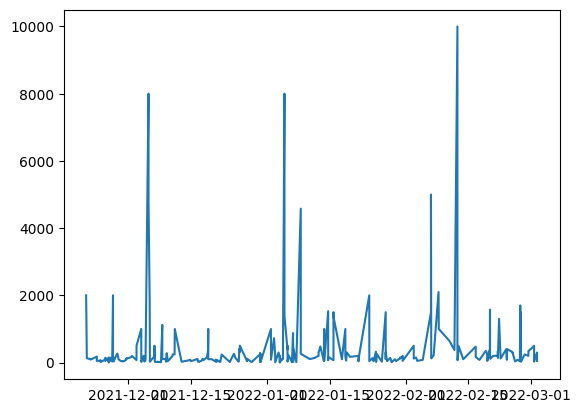

In [ ]:
# Import matplotlib and plot the trend of expenses over time
import matplotlib.pyplot as plt
plt.plot(df['Date'], df['INR'])

In [ ]:
# Extract the weekday name for each date and store it in a new column
df['day_name'] = df['Date'].dt.day_name()

In [ ]:
# Display first 5 rows to confirm the creation of the 'day_name' column
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday


<Axes: xlabel='day_name'>

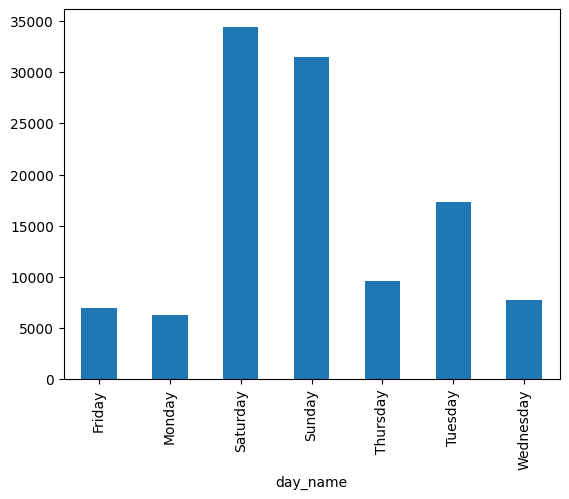

In [ ]:
# Group expenses by day of the week, sum them, and plot a bar chart
df.groupby('day_name')['INR'].sum().plot(kind='bar')

In [ ]:
# Extract the month name for each date and store it in a new column
df['month_name'] = df['Date'].dt.month_name()

In [ ]:
# Display the first 5 rows to confirm the creation of the 'month_name' column
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday,March
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday,March
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday,March
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday,March
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday,March


<Axes: xlabel='month_name'>

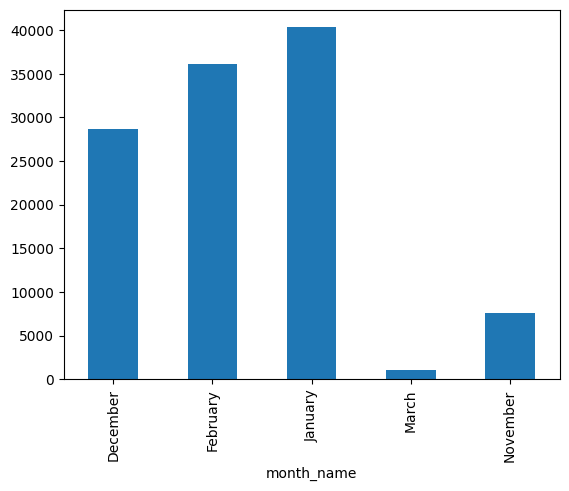

In [ ]:
# Group expenses by month name, sum them, and plot a bar chart
df.groupby('month_name')['INR'].sum().plot(kind='bar')

<Axes: xlabel='month_name'>

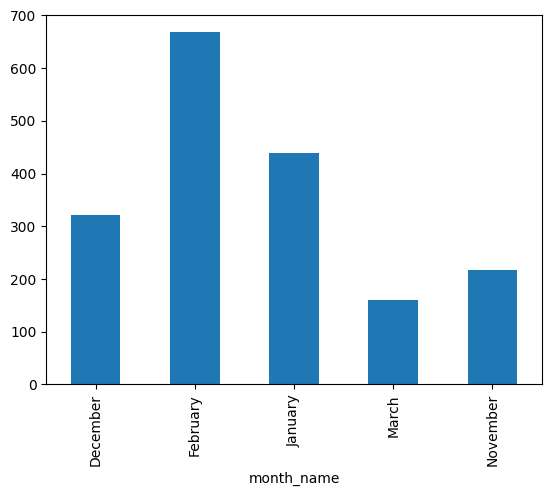

In [ ]:
# Group expenses by month name, calculate the average expense, and plot a bar chart
df.groupby('month_name')['INR'].mean().plot(kind='bar')

In [ ]:
# Filter the expense DataFrame for dates that are exactly at the end of a month
df[df['Date'].dt.is_month_end]

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
7,2022-02-28 11:56:00,CUB - online payment,Food,NaN,Pizza,339.15,Expense,NaN,339.15,INR,339.15,Monday,February
8,2022-02-28 11:45:00,CUB - online payment,Other,NaN,From kumara,200.00,Income,NaN,200.00,INR,200.00,Monday,February
61,2022-01-31 08:44:00,CUB - online payment,Transportation,NaN,Vnr to apk,50.00,Expense,NaN,50.00,INR,50.00,Monday,January
62,2022-01-31 08:27:00,CUB - online payment,Other,NaN,To vicky,200.00,Expense,NaN,200.00,INR,200.00,Monday,January
63,2022-01-31 08:26:00,CUB - online payment,Transportation,NaN,To ksr station,153.00,Expense,NaN,153.00,INR,153.00,Monday,January
242,2021-11-30 14:24:00,CUB - online payment,Gift,NaN,Bharath birthday,115.00,Expense,NaN,115.00,INR,115.00,Tuesday,November
243,2021-11-30 14:17:00,CUB - online payment,Food,NaN,Lunch with company,128.00,Expense,NaN,128.00,INR,128.00,Tuesday,November
244,2021-11-30 10:11:00,CUB - online payment,Food,NaN,Breakfast,70.00,Expense,NaN,70.00,INR,70.00,Tuesday,November
